# Встреча 6. Решение, мемо, портфель: теория

> **Время:** 35 минут · **Дальше:** `practice.ipynb` · **Данные:** `../data/checkout_ab.csv` (блок 2)

Тест чекаута отработал две недели. Осталось три шага: превратить оценку в решение, не «продать» случайный сегмент и положить результат в портфель так, чтобы следующий тест опирался на честную историю.

| Блок | Тезис | Минут |
| --- | --- | :---: |
| 1 | Решаем против порога, а не против нуля; эффект и ДИ — в деньгах | 10 |
| 2 | Типовые ловушки интерпретации: ratio-метрики и парадокс Симпсона | 8 |
| 3 | Сегменты: скрытая множественность и проклятие победителя | 9 |
| 4 | Портфель: fixed vs random effects, I², shrinkage, здоровье процесса | 8 |

### Библиотеки и параметры кейса

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2, norm
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'


# Кейс чекаута (встреча 1): выручка, затраты и горизонт
WEEKLY_REVENUE = 137_000_000          # ₽ в неделю
COSTS = 3_000_000 + 10_000_000 + 12 * 1_000_000   # тест + внедрение + поддержка за год, ₽
WEEKS = 52                            # горизонт, недель
P_A = 0.70                            # базовая конверсия
BE_PP = COSTS / (WEEKLY_REVENUE * WEEKS) * P_A * 100   # точка безубыточности, п.п.


def money(delta_pp):
    """Чистый эффект внедрения за горизонт, млн ₽: доп. выручка минус затраты."""
    return (np.asarray(delta_pp) / (100 * P_A) * WEEKLY_REVENUE * WEEKS - COSTS) / 1e6


print(f"Точка безубыточности: {BE_PP:.3f} п.п.; 1 п.п. конверсии = {money(1) - money(0):.1f} млн ₽ выручки за год")

Точка безубыточности: 0.246 п.п.; 1 п.п. конверсии = 101.8 млн ₽ выручки за год


## 1. Решение — против порога, а не против нуля (10 минут)

**Тезис.** Значимость отвечает на вопрос «эффект не ноль?». Бизнесу нужен другой ответ: «окупится ли внедрение?». Поэтому ДИ сравниваем с точкой безубыточности (BE), а не с нулём, и переводим в деньги.

Для чекаута порог посчитан на встрече 1: внедрение окупает тест, внедрение и год поддержки (25 млн ₽), если конверсия растёт хотя бы на $\delta_{BE} = 0.246$ п.п. Порог посчитан для базы $p_A = 0.70$. В практике база берётся из очищенных данных ($\hat p_A = 69.87\%$), и 1 п.п. стоит 102.0 млн ₽ вместо 101.8 — на порог и решение это не влияет. Перевод в деньги линейный:

$$
\text{Деньги}(\delta) = \frac{\delta}{p_A}\cdot R_{\text{нед}}\cdot 52 - 25\ \text{млн ₽}, \qquad \text{Деньги}(\delta_{BE}) = 0.
$$

Границы ДИ переводятся в деньги той же формулой. Получаем «ДИ в деньгах» — его и пишем в мемо.

Четыре типовых исхода теста на одном графике:

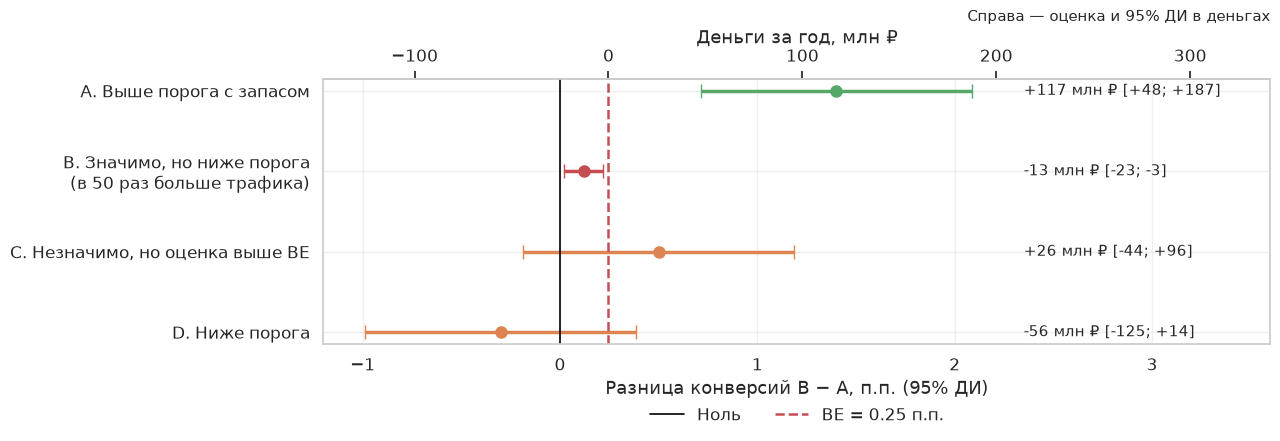

In [2]:
cases = [  # (подпись, оценка п.п., SE п.п.)
    ('A. Выше порога с запасом', 1.40, 0.35),
    ('B. Значимо, но ниже порога\n(в 50 раз больше трафика)', 0.12, 0.05),
    ('C. Незначимо, но оценка выше BE', 0.50, 0.35),
    ('D. Ниже порога', -0.30, 0.35),
]
fig, ax = plt.subplots(figsize=(13, 4.8))
for i, (label, est, se) in enumerate(cases):
    y = len(cases) - i
    lo, hi = est - 1.96 * se, est + 1.96 * se
    color = GREEN if lo > BE_PP else RED if hi < BE_PP else ORANGE
    ax.errorbar(est, y, xerr=1.96 * se, fmt='o', color=color, capsize=5, lw=2.5, ms=8)
    ax.text(2.35, y, f"{money(est):+.0f} млн ₽ [{money(lo):+.0f}; {money(hi):+.0f}]", va='center', fontsize=11)
ax.axvline(0, color='black', lw=1.2, label='Ноль')
ax.axvline(BE_PP, color=RED, ls='--', lw=1.8, label=f'BE = {BE_PP:.2f} п.п.')
ax.set_yticks(range(len(cases), 0, -1), [c[0] for c in cases])
ax.set_xlim(-1.2, 3.6)
ax.set_xlabel('Разница конверсий B − A, п.п. (95% ДИ)')
top = ax.secondary_xaxis('top', functions=(lambda d: money(d), lambda m: (m * 1e6 + COSTS) * 100 * P_A / (WEEKLY_REVENUE * WEEKS)))
top.set_xlabel('Деньги за год, млн ₽')
ax.set_title('Справа — оценка и 95% ДИ в деньгах', loc='right', fontsize=11)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

* **A** — нижняя граница ДИ выше порога: внедрение выгодно с запасом. Так выглядит наш чекаут (практика, задание 1).
* **B** — классика «значимо = выгодно». При большом трафике ДИ узкий и отделён от нуля, но целиком ниже порога: внедрение убыточно.
* **C** — незначимо против нуля, но оценка выше BE. По правилу встречи 1 ($\alpha = 0.5$ против BE) внедряем: в среднем это выгодно, а провал ловит мониторинг. Цену риска честно пишем в мемо: нижняя граница — минус 44 млн ₽.
* **D** — весь ДИ «в зоне вокруг нуля», оценка ниже порога: не внедряем.

Насколько часто правило «значимо против нуля» ошибается в деньгах? Разыграем 200 тыс. тестов с ожиданиями встречи 1: истинный относительный эффект $\theta \sim N(0,\ 1.5\%)$, то есть разница конверсий $\sim N(0,\ 1.05\ \text{п.п.})$.

In [3]:
rng = np.random.default_rng(6)
true_pp = rng.normal(0, 0.015 * P_A * 100, 200_000)
rows = []
for n_b in [21_000, 2_100_000]:
    se = 100 * np.sqrt(P_A * (1 - P_A) * (1 / (4 * n_b) + 1 / n_b))
    est = true_pp + rng.normal(0, se, true_pp.size)
    for rule, shipped in [('значимо против нуля (α = 0.05)', est > 1.96 * se), ('оценка выше BE (встреча 1)', est > BE_PP)]:
        rows.append({'n_B': f'{n_b:,}'.replace(',', ' '), 'SE, п.п.': f'{se:.3f}', 'Правило': rule,
                     'Внедряем, %': 100 * shipped.mean(),
                     'Невыгодных среди внедрённых, %': 100 * (true_pp[shipped] < BE_PP).mean(),
                     'Пропущено выгодных, %': 100 * (~shipped[true_pp > BE_PP]).mean(),
                     'Деньги на тест, млн ₽': (shipped * money(true_pp)).mean()})
pd.DataFrame(rows).set_index(['n_B', 'Правило']).round(1)

SE, п.п.  Внедряем, %  \
n_B       Правило                                                
21 000    значимо против нуля (α = 0.05)    0.354         26.5   
          оценка выше BE (встреча 1)        0.354         41.2   
2 100 000 значимо против нуля (α = 0.05)    0.035         47.3   
          оценка выше BE (встреча 1)        0.035         40.6   

                                          Невыгодных среди внедрённых, %  \
n_B       Правило                                                          
21 000    значимо против нуля (α = 0.05)                             2.5   
          оценка выше BE (встреча 1)                                13.0   
2 100 000 значимо против нуля (α = 0.05)                            14.1   
          оценка выше BE (встреча 1)                                 1.3   

                                          Пропущено выгодных, %  \
n_B       Правило                                                 
21 000    значимо против нуля (α = 0.05)                   36.4   
          оценка выше BE (встреча 1)                       11.8   
2 100 000 значимо против нуля (α = 0.05)                    0.0   
          оценка выше BE (встреча 1)                        1.4   

                                          Деньги на тест, млн ₽  
n_B       Правило                                                
21 000    значимо против нуля (α = 0.05)                   26.5  
          оценка выше BE (встреча 1)                       29.0  
2 100 000 значимо против нуля (α = 0.05)                   30.6  
          оценка выше BE (встреча 1)                       31.2

Два вывода.

1. При $n_B = 21$ тыс. правило «значимо против нуля» слишком строгое. Оно пропускает 36% выгодных вариантов и зарабатывает 26.5 млн ₽ на тест против 29.0 млн ₽ у правила «выше BE».
2. При стократном трафике то же правило внедряет невыгодные варианты: их 14% среди внедрённых против 1.3% у правила «выше BE». Порог против нуля не знает, сколько стоит внедрение: чем точнее тест, тем чаще «значимо» означает «значимо, но мелко».

**Guardrail — non-inferiority.** Для метрики «не навредить» вопрос другой: доказано ли, что вред меньше допустимого? $H_0: \delta \ge m$ (граница $m$ записана до запуска). Проходим, если односторонняя верхняя 95%-граница ниже $m$. «Незначимо против нуля» этого не доказывает.

**Почему α разные.** Ошибка по OEC стоит денег примерно линейно и ловится мониторингом. Поэтому правило встречи 1 — $\alpha = 0.5$ против BE: максимум ожидаемой прибыли. Вред по guardrail (сбои оплаты, отток, поддержка) плохо виден и плохо обратим. Поэтому бремя доказательства — на новом варианте, $\alpha = 0.05$.

**Структура мемо** (шаблон — `memo_template.md`, заполняем в практике):

1. **Решение в первой строке**: внедряем / не внедряем как есть / не внедряем — и почему одной фразой.
2. **Эффект** по OEC: оценка и 95% ДИ в метрике и в деньгах за горизонт.
3. **Порог** и правило решения, зафиксированные до запуска.
4. **Guardrail** — прошли ли non-inferiority; качество данных (SRM, очистка).
5. **Риски и допущения** — что должно быть правдой, чтобы деньги сошлись.
6. **Сегменты** — только преднамеченные; разведочные — как гипотезы.
7. **Что дальше** — следующий шаг, владелец, срок.

## 2. Типовые ловушки интерпретации (8 минут)

**Тезис.** Цифра в отчёте может быть верной, а вывод из неё — ложным. Две самые частые ловушки: ratio-метрика, у которой знаменатель зависит от варианта, и смешение групп с разными долями во времени (парадокс Симпсона). Третья — «значимо = выгодно» — уже разобрана в блоке 1.

### Ratio: средний чек на нашем чекауте

Средний чек = выручка / число заказов. Знаменатель — покупатели, а их состав меняет сам вариант. Посмотрим на данные теста (очистка — как на встрече 3).

In [4]:
raw = pd.read_csv('../data/checkout_ab.csv')
dedup = raw.drop_duplicates()
in_both = dedup.groupby('user_id')['group'].nunique().gt(1)
df = dedup[~dedup['user_id'].isin(in_both[in_both].index)]

table = df.groupby('group').agg(users=('user_id', 'size'), CR=('converted', 'mean'), ARPU=('revenue', 'mean'))
table['Средний чек'] = df[df['converted'] == 1].groupby('group')['revenue'].mean()
change = table.loc['B'] / table.loc['A'] - 1
print('Изменение B к A: ' + ', '.join(f"{name} {value:+.1%}" for name, value in change.drop('users').items()))
table.round(3)

Изменение B к A: CR +2.0%, ARPU +1.5%, Средний чек -0.5%


,users,CR,ARPU,Средний чек
group,,,,
A,83878,0.699,2604.419,3727.684
B,21082,0.713,2642.374,3707.837


Средний чек в B упал на 0.5%, а выручка на пользователя выросла на 1.5%. Противоречия нет: $\text{ARPU} = \text{CR} \times \text{чек}$, и $(1 + 2.0\%)(1 - 0.5\%) \approx 1 + 1.5\%$. Новый чекаут довёл до заказа «маргинальных» покупателей, у которых чек чуть ниже среднего. Сравнение чека — это сравнение **разных популяций**: покупатели A и покупатели B уже не рандомизированы.

Правила для ratio-метрик:

* решение принимаем по метрике **на пользователя** (единице рандомизации): ARPU, конверсия;
* чек, «выручка на заказ», CTR по показам — диагностика механизма, а не критерий;
* у ratio-метрики свой SE: наблюдения в знаменателе зависимы, нужен дельта-метод или линеаризация (встреча 2), иначе SE занижен.

### Парадокс Симпсона: раскатка по шагам

Типичная ситуация: первую неделю вариант B получает 5% трафика (осторожный старт), вторую — 50%. Конверсия в первую неделю выше (распродажа). Внутри **каждой** недели B лучше A на 1 п.п.

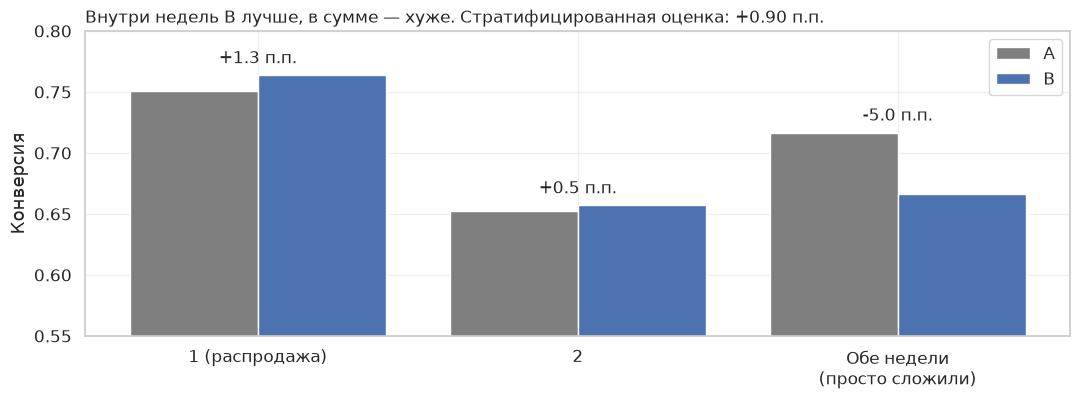

In [5]:
rng = np.random.default_rng(3)
weeks = pd.DataFrame({'Неделя': ['1 (распродажа)', '2'], 'users': [50_000, 50_000],
                      'share_b': [0.05, 0.50], 'cr_a': [0.75, 0.65]})
rows = []
for _, w in weeks.iterrows():
    for group, share, cr in [('A', 1 - w.share_b, w.cr_a), ('B', w.share_b, w.cr_a + 0.01)]:
        n = int(w.users * share)
        rows.append({'Неделя': w['Неделя'], 'group': group, 'n': n, 'orders': rng.binomial(n, cr)})
sim = pd.DataFrame(rows)
by_week = sim.pivot(index='Неделя', columns='group', values=['n', 'orders'])
cr_week = by_week['orders'] / by_week['n']
pooled = sim.groupby('group')[['n', 'orders']].sum()
cr_pooled = pooled['orders'] / pooled['n']
# Честная агрегация: разница внутри недели, взвешенная по общему трафику недели
weights = by_week['n'].sum(axis=1) / by_week['n'].values.sum()
stratified = ((cr_week['B'] - cr_week['A']) * weights).sum()

fig, ax = plt.subplots(figsize=(11, 4.2))
labels = list(cr_week.index) + ['Обе недели\n(просто сложили)']
xa = np.arange(3)
ax.bar(xa - 0.2, [*cr_week['A'], cr_pooled['A']], 0.4, color=GRAY, label='A')
ax.bar(xa + 0.2, [*cr_week['B'], cr_pooled['B']], 0.4, color=BLUE, label='B')
for x, a, b in zip(xa, [*cr_week['A'], cr_pooled['A']], [*cr_week['B'], cr_pooled['B']]):
    ax.text(x, max(a, b) + 0.01, f"{100 * (b - a):+.1f} п.п.", ha='center', fontsize=12)
ax.set_xticks(xa, labels)
ax.set_ylim(0.55, 0.8)
ax.set_ylabel('Конверсия')
ax.set_title(f'Внутри недель B лучше, в сумме — хуже. Стратифицированная оценка: {100 * stratified:+.2f} п.п.', loc='left', fontsize=12)
ax.legend()
plt.tight_layout()
plt.show()

В сумме B «проигрывает» около 5 п.п. (−5.0 на графике; по параметрам без шума — −4.6): почти весь его трафик пришёлся на неделю с низкой базой. Причина — доля B менялась во времени вместе с базовой конверсией.

Что делать:

* считать эффект **внутри страт** (дней, недель, шагов раскатки) и взвешивать по общему трафику страты — это и есть стратифицированная оценка;
* или анализировать только период с постоянным сплитом;
* SRM по дням — первый сигнал, что доли менялись (встреча 3).

Тот же механизм встречается в сегментах: если B чаще достаётся мобильным, а у мобильных ниже база, общий эффект врёт.

## 3. Сегменты и CATE: скрытая множественность (9 минут)

**Тезис.** Каждый разрез — это ещё одна гипотеза. 10 разрезов по 2–4 значения — уже 30 сравнений. Без поправки хотя бы одно «выстрелит» почти наверняка. А сегмент, выбранный как лучший, переоценён: при подтверждении его эффект «сдуется».

Условный эффект в сегменте (CATE — conditional average treatment effect) оценивают так же, как средний эффект, но на подвыборке. Вопрос «отличается ли сегмент» — это тест **взаимодействия**: разница эффектов «сегмент против остальных», а не «эффект в сегменте против нуля».

Симуляция: эффект одинаков во всех сегментах (гетерогенности нет). Слева — вероятность найти хотя бы один «особый» сегмент при $K$ сравнениях. Справа — 20 сегментов с одинаковым эффектом +1 п.п.: оценка лучшего из них и та же оценка в подтверждающем тесте.

Лучший сегмент: средняя оценка +1.93 п.п., в подтверждающем тесте +1.00 п.п.


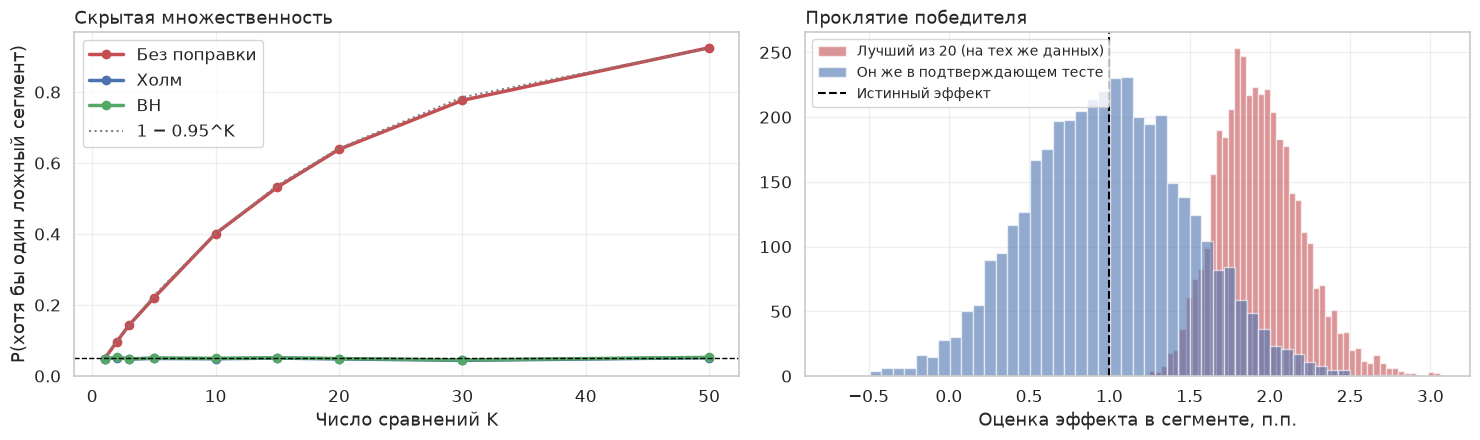

In [6]:
rng = np.random.default_rng(11)
K_grid = np.array([1, 2, 3, 5, 10, 15, 20, 30, 50])
reps = 4_000
fwer = {'Без поправки': [], 'Холм': [], 'BH': []}
for K in K_grid:
    p = np.sort(2 * norm.sf(np.abs(rng.normal(size=(reps, K)))), axis=1)
    fwer['Без поправки'].append((p[:, 0] < 0.05).mean())
    # Хоть одно отклонение: у Холма — если p_(1) < α/K, у BH — если p_(i) ≤ i·α/K хоть для одного i
    fwer['Холм'].append((p[:, 0] < 0.05 / K).mean())
    fwer['BH'].append((p <= 0.05 * np.arange(1, K + 1) / K).any(axis=1).mean())

# Проклятие победителя: 20 сегментов, у всех истинный эффект +1 п.п., SE в сегменте 0.5 п.п.
n_seg, true_effect, se_seg = 20, 1.0, 0.5
estimates = true_effect + rng.normal(0, se_seg, (reps, n_seg))
best = estimates.argmax(axis=1)
best_estimate = estimates[np.arange(reps), best]
confirm = true_effect + rng.normal(0, se_seg, reps)       # тот же сегмент в новом тесте
print(f"Лучший сегмент: средняя оценка {best_estimate.mean():+.2f} п.п., в подтверждающем тесте {confirm.mean():+.2f} п.п.")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for (name, values), color in zip(fwer.items(), [RED, BLUE, GREEN]):
    axes[0].plot(K_grid, values, 'o-', color=color, lw=2.5, label=name)
axes[0].plot(K_grid, 1 - 0.95 ** K_grid, ':', color=GRAY, label='1 − 0.95^K')
axes[0].axhline(0.05, color='black', ls='--', lw=1)
axes[0].set_xlabel('Число сравнений K')
axes[0].set_ylabel('P(хотя бы один ложный сегмент)')
axes[0].set_title('Скрытая множественность', loc='left')
axes[0].legend()
axes[1].hist(best_estimate, bins=50, color=RED, alpha=0.6, label='Лучший из 20 (на тех же данных)')
axes[1].hist(confirm, bins=50, color=BLUE, alpha=0.6, label='Он же в подтверждающем тесте')
axes[1].axvline(true_effect, color='black', ls='--', lw=1.5, label='Истинный эффект')
axes[1].set_xlabel('Оценка эффекта в сегменте, п.п.')
axes[1].set_title('Проклятие победителя', loc='left')
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.show()

* При 20 разрезах без поправки «особый» сегмент находится в 64% случаев, хотя его нет. Холм и BH держат 5%: когда гетерогенности нет совсем, BH контролирует ту же вероятность, что и Холм.
* Лучший из 20 одинаковых сегментов в среднем показывает +1.93 п.п. вместо +1. В подтверждающем тесте он возвращается к +1 п.п. Это регрессия к среднему, а не «эффект выдохся».

**Сколько сегментов можно смотреть.** Тест взаимодействия дорогой. Если сегмент — половина трафика, разница эффектов «сегмент против остальных» имеет SE в 2 раза больше SE общего эффекта:

$$
SE_{\text{diff}} = \sqrt{SE_1^2 + SE_2^2} = SE_{\text{общ}}\sqrt{\tfrac{1}{0.5} + \tfrac{1}{0.5}} = 2\,SE_{\text{общ}}.
$$

Чтобы увидеть разницу того же размера, что и общий эффект, нужно в 4 раза больше трафика. Для сегмента в 10% трафика — в 11 раз больше. Отсюда регламент:

1. **Преднамеченные** сегменты — 1–2, записаны в дизайн-доке до запуска, с гипотезой о механизме. По ним отчитываемся в мемо.
2. **Разведочные** — сколько угодно, но с поправкой (BH, если цель — список кандидатов; Холм, если ошибка дорогая) и с пометкой «гипотеза».
3. **Сегмент найден → подтверждающий тест** на этом сегменте. Таргетированную раскатку по разведочному сегменту без подтверждения не делаем.
4. Отчитываемся о числе просмотренных разрезов, а не только о «выстреливших».

Модели CATE (causal forest, meta-learners) — та же множественность в автоматическом режиме: сегмент ищет алгоритм. Правило то же: найденное проверяем на отложенных данных или в новом тесте.

## 4. Портфель: что мы узнали за квартал (8 минут)

**Тезис.** Один тест — шумная оценка. Портфель тестов — данные о том, какие эффекты у нас вообще бывают. Мета-анализ объединяет тесты и отвечает на два вопроса: каков средний эффект и насколько тесты различаются.

* **Fixed effects**: все тесты оценивают один эффект, веса $w_i = 1/SE_i^2$, $\hat\mu_{FE} = \sum w_i\hat\theta_i / \sum w_i$.
* **Неоднородность**: $Q = \sum w_i(\hat\theta_i - \hat\mu_{FE})^2 \sim \chi^2_{k-1}$ при однородности; $I^2 = \max\big(0, \frac{Q - (k-1)}{Q}\big)$ — доля разброса, которую не объясняет шум (25% — низкая, 50% — умеренная, 75% — высокая).
* **Random effects** (DerSimonian–Laird): $\theta_i \sim N(\mu, \tau^2)$, $\hat\tau^2 = \max\big(0, \frac{Q - (k-1)}{\sum w_i - \sum w_i^2/\sum w_i}\big)$, веса $1/(SE_i^2 + \hat\tau^2)$. ДИ шире: он учитывает, что тесты разные.
* **Shrinkage** (эмпирический Байес): оценка теста сжимается к среднему портфеля, $\tilde\theta_i = \hat\mu + B_i(\hat\theta_i - \hat\mu)$, $B_i = \frac{\tau^2}{\tau^2 + SE_i^2}$. Шумные тесты сжимаются сильнее. Сжимаем только к среднему **сравнимых** тестов. Если в портфеле есть выброс другого класса, его не сжимают к общему среднему, а разбирают отдельно (практика, задание 4). Среднее портфеля shrinkage почти не меняет. Он меняет оценки отдельных тестов, и сильнее всего — оценки «победителей».

Симуляция: 10 тестов, истинные эффекты $\theta_i \sim N(0.2,\ 0.15^2)$ п.п., SE от 0.08 до 0.25 п.п. Сначала один портфель на forest plot, затем 2 000 портфелей: покрытие среднего и ошибка оценок отдельных тестов.

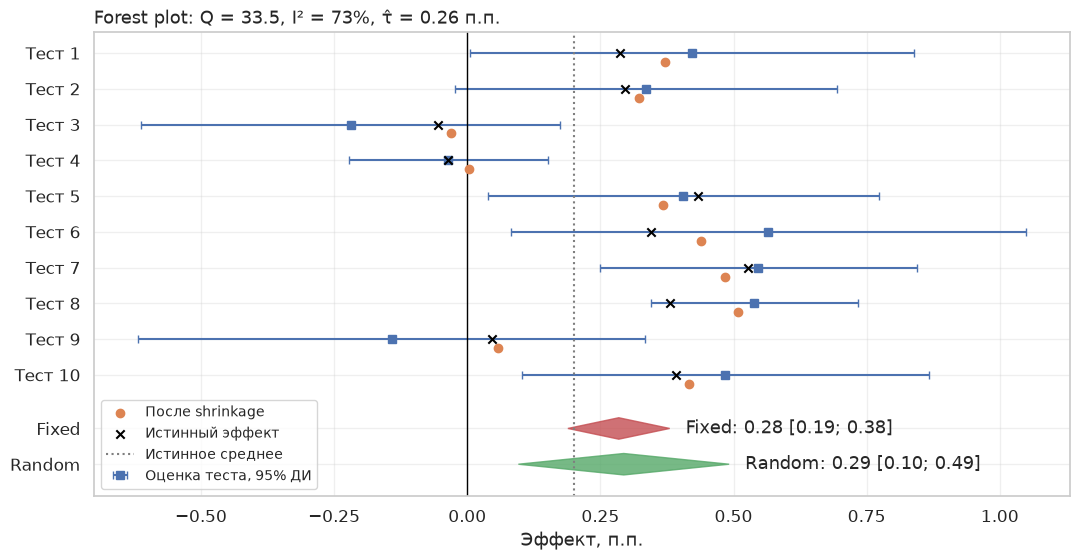

Покрытие среднего 95% ДИ: fixed 79%, random 92%
Средняя ошибка оценки теста (RMSE): исходная 0.171 п.п., после shrinkage 0.122 п.п.


In [7]:
def meta(effect, se):
    """Fixed и random effects (DerSimonian–Laird) для эффектов и их SE."""
    effect, se = np.asarray(effect, float), np.asarray(se, float)
    w = 1 / se ** 2
    fe = np.sum(w * effect) / w.sum()
    q = np.sum(w * (effect - fe) ** 2)
    k = effect.size
    tau2 = max(0.0, (q - (k - 1)) / (w.sum() - np.sum(w ** 2) / w.sum()))
    w_re = 1 / (se ** 2 + tau2)
    re = np.sum(w_re * effect) / w_re.sum()
    return {'fe': fe, 'se_fe': 1 / np.sqrt(w.sum()), 'q': q, 'i2': max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0,
            'tau2': tau2, 're': re, 'se_re': 1 / np.sqrt(w_re.sum()),
            'shrunk': re + tau2 / (tau2 + se ** 2) * (effect - re)}


rng = np.random.default_rng(21)
k, mu, tau = 10, 0.2, 0.15


def portfolio():
    se = rng.uniform(0.08, 0.25, k)
    theta = rng.normal(mu, tau, k)
    return theta, theta + rng.normal(0, se), se


theta, est, se = portfolio()
m = meta(est, se)
fig, ax = plt.subplots(figsize=(11, 5.8))
rows = np.arange(k)[::-1] + 3
ax.errorbar(est, rows, xerr=1.96 * se, fmt='s', color=BLUE, capsize=3, label='Оценка теста, 95% ДИ')
ax.scatter(m['shrunk'], rows - 0.25, color=ORANGE, zorder=3, label='После shrinkage')
ax.scatter(theta, rows, marker='x', color='black', zorder=4, label='Истинный эффект')
for y, centre, half, color, name in [(1.5, m['fe'], 1.96 * m['se_fe'], RED, 'Fixed'), (0.5, m['re'], 1.96 * m['se_re'], GREEN, 'Random')]:
    ax.fill([centre - half, centre, centre + half, centre], [y, y + 0.3, y, y - 0.3], color=color, alpha=0.8)
    ax.text(centre + half + 0.03, y, f"{name}: {centre:.2f} [{centre - half:.2f}; {centre + half:.2f}]", va='center')
ax.axvline(0, color='black', lw=1)
ax.axvline(mu, color=GRAY, ls=':', lw=1.5, label='Истинное среднее')
ax.set_yticks([*rows, 1.5, 0.5], [f'Тест {i + 1}' for i in range(k)] + ['Fixed', 'Random'])
ax.set_xlabel('Эффект, п.п.')
ax.set_title(f"Forest plot: Q = {m['q']:.1f}, I² = {m['i2']:.0%}, τ̂ = {np.sqrt(m['tau2']):.2f} п.п.", loc='left')
ax.legend(loc='lower left', fontsize=10)
plt.tight_layout()
plt.show()

cover = {'Fixed': 0, 'Random': 0}
mse_raw = mse_shrunk = 0.0
for _ in range(2_000):
    theta, est, se = portfolio()
    m = meta(est, se)
    cover['Fixed'] += abs(m['fe'] - mu) < 1.96 * m['se_fe']
    cover['Random'] += abs(m['re'] - mu) < 1.96 * m['se_re']
    mse_raw += np.mean((est - theta) ** 2) / 2_000
    mse_shrunk += np.mean((m['shrunk'] - theta) ** 2) / 2_000
print(f"Покрытие среднего 95% ДИ: fixed {cover['Fixed'] / 2_000:.0%}, random {cover['Random'] / 2_000:.0%}")
print(f"Средняя ошибка оценки теста (RMSE): исходная {np.sqrt(mse_raw):.3f} п.п., после shrinkage {np.sqrt(mse_shrunk):.3f} п.п.")

* **Fixed vs random.** Когда тесты разные ($\tau > 0$), ДИ fixed effects слишком узкий: он накрывает истинное среднее заметно реже заявленных 95%. Random effects честнее. При малом $k$ даже DL немного не дотягивает — для отчёта есть поправка Хартунга–Кнаппа.
* **Shrinkage** уменьшает ошибку оценок отдельных тестов: для портфеля с разбросом эффектов это лучше, чем верить каждой оценке как есть. Сжатые оценки — честная база для ожиданий следующего теста (вход встречи 1) и для «сколько мы заработали за квартал».
* **I²** — не тест, а описание. Высокий I² говорит «не усредняйте вслепую»: ищите тест-выброс и причину различий.

**Ревью-борд.** Регулярная встреча, где команда защищает мемо перед коллегами. Его цель — не «одобрить», а поймать ошибки: правило задним числом, guardrail без non-inferiority, сегмент без поправки, деньги без допущений. Рубрика на 5 пунктов — в `memo_template.md`.

**Здоровье процесса** смотрим по портфелю, а не по отдельным тестам:

| Метрика | Что показывает | Тревожный сигнал |
| --- | --- | --- |
| Доля прошедших правило | оценка выше BE своего теста (правило встречи 1) | при α = 0.5 против BE доля выше «трети» — это нормально; резкий рост между кварталами — проверьте, не менялись ли правила задним числом |
| Доля значимых выигрышей | p < 0.05 и эффект > 0 — так считают в отрасли | > 50% подозрительно, ищите p-hacking; у Microsoft значимо выигрывает около трети идей |
| Средний эффект внедрённых (после shrinkage) | реальная отдача портфеля | сумма «сырых» эффектов сильно больше суммы сжатых |
| Доля вредных и нулевых | идеи, от которых тест спас | 0% — нулевые тесты не доходят до базы знаний |
| Тесты с планом до запуска | дисциплина | любые решения «по факту» |
| I² портфеля | насколько тесты сравнимы | > 75%: портфель смешивает разные продукты или есть выброс |

Нулевой результат — тоже знание: он сужает ожидания и экономит трафик следующих тестов. Если в базу попадают только победы, мета-анализ завышает эффекты так же, как публикационное смещение в науке.

**Дальше — практика:** решение и деньги по чекауту, сегменты горящих предложений, мета-анализ портфеля из шести тестов и мемо.